# KAIST multispectral pedestrian dataset: annotations, videos and clips, 2026-11-25

Compares the two annotation sets of KAIST (Hwang et al., CVPR 2015) that are under `$IRWM_DATA_ROOT`:

| Name here | Path | Format |
|---|---|---|
| **Original** | `kaist-cvpr15/annotations-xml-new/setXX/VYYY/I#####.xml` | one VOC-style XML per frame, shared by both cameras |
| **Paired** | `kaist-paired/annotations/setXX/VYYY/{lwir,visible}/I#####.txt` | one `bbGt v3` text file per frame **and per camera** |

*Paired* is KAIST-Paired from Zhang et al., "Weakly Aligned Cross-Modal Learning for Multispectral Pedestrian
Detection" (ICCV 2019, [arXiv:1901.02645](https://arxiv.org/abs/1901.02645)). It relabels each camera separately,
so a box can be off by a few pixels between thermal and RGB, and it marks boxes seen in only one camera as `unpaired`.
`kaist-cvpr15/annotations-xml-new-sanitized` is also on disk; it is byte-identical to `annotations-xml-new` (checked
below), so this notebook treats them as one set.

Frame files keep the original 20 Hz frame index (`I00019` is the 20th frame of its video), so the two sets can be
lined up frame by frame.

1. Number of samples (annotated frames), original vs paired
2. Number of videos
3. Number of objects per class, in total and per video
4. Clips of **5 frames at ≈ 6 Hz or 5 Hz**, not overlapping in time: the most that can be cut from each annotation
   set, in total and per video, with every frame labelled or only the last one

In [16]:
import filecmp
import os
import re
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from irwm.utils.paths import load_env

load_env()
DATA = Path(os.environ["IRWM_DATA_ROOT"])
KAIST = DATA / "kaist-cvpr15"
ORIG_ANN = KAIST / "annotations-xml-new"
SANI_ANN = KAIST / "annotations-xml-new-sanitized"
PAIRED_ANN = DATA / "kaist-paired" / "annotations"
FPS = 20  # KAIST frame rate (paper); there are no per-frame timestamps on disk
MODS = ["lwir", "visible"]


def md_table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(f"{c:,}" if isinstance(c, (int, np.integer)) else str(c) for c in r) + " |"
            for r in rows]
    display(Markdown("\n".join(out)))


def frame_of(name):  # "I01234.xml" -> 1234
    return int(name[1:6])

In [17]:
# Plot style as in the other notebooks. Fixed series colours (categorical slots 1-3, in order): original = blue,
# paired thermal = orange, paired visible = aqua. Every chart names its series in a legend, so colour is never the
# only cue.
C_ORIG, C_LWIR, C_VIS = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False,
})

## 0. Load everything

* **Images:** the frame indices in `images/setXX/VYYY/{lwir,visible}/`.
* **Original:** class names from every XML (`<name>` tags).
* **Paired:** the first token of every non-comment line (`label x y w h ...`) of every text file, per camera.
* **Split and day/night** come from the official image lists (`imageSets/{train,test}-{day,night}-*.txt`), not
  from hard-coded set numbers.

In [18]:
VIDEOS = sorted((s.name, v.name) for s in (KAIST / "images").iterdir() for v in s.iterdir())
vid = lambda sv: f"{sv[0]}/{sv[1]}"

NAME_RE = re.compile(r"<name>([^<]*)</name>")


def load_video(sv):
    s, v = sv
    img = {m: sorted(frame_of(f) for f in os.listdir(KAIST / "images" / s / v / m)) for m in MODS}
    orig = {}
    for f in os.listdir(ORIG_ANN / s / v):
        if f.endswith(".xml"):
            orig[frame_of(f)] = Counter(NAME_RE.findall((ORIG_ANN / s / v / f).read_text()))
    paired = {}
    for m in MODS:
        d = PAIRED_ANN / s / v / m
        paired[m] = {}
        for f in (os.listdir(d) if d.exists() else []):
            lines = (d / f).read_text().splitlines()
            paired[m][frame_of(f)] = Counter(l.split()[0] for l in lines if l.strip() and not l.startswith("%"))
    return sv, img, orig, paired


with ThreadPoolExecutor(16) as ex:
    loaded = list(ex.map(load_video, VIDEOS))
IMG = {sv: img for sv, img, _, _ in loaded}
ORIG = {sv: o for sv, _, o, _ in loaded}        # ORIG[sv][frame] -> Counter(class)
PAIRED = {sv: p for sv, _, _, p in loaded}      # PAIRED[sv][mod][frame] -> Counter(class)


def videos_in(list_name):
    lines = (KAIST / "imageSets" / list_name).read_text().split()
    return {tuple(l.split("/")[:2]) for l in lines}


SPLIT, TOD = {}, {}
for split, n in [("train", "02"), ("test", "01")]:
    for tod in ["day", "night"]:
        for sv in videos_in(f"{split}-{tod}-{n}.txt"):
            SPLIT[sv], TOD[sv] = split, tod
print(f"{len(VIDEOS)} videos, {sum(len(IMG[sv]['lwir']) for sv in VIDEOS):,} frames per camera")

41 videos, 95,324 frames per camera


### Sanity checks

* `annotations-xml-new-sanitized` is byte-identical to `annotations-xml-new` (the only extra file is a Windows
  `.lnk` shortcut).
* Every video is in exactly one split and one day/night list; both cameras have the same frames; frame indices run
  0…N−1 with no holes.
* The original set has one XML per image, so it covers every frame.
* The paired set has the same frames for `lwir` and `visible`, and they are a subset of the image frames.

In [19]:
n_same, diff, missing = 0, [], []
for sv in VIDEOS:
    names = sorted(f for f in os.listdir(ORIG_ANN / sv[0] / sv[1]) if f.endswith(".xml"))
    match, mismatch, err = filecmp.cmpfiles(ORIG_ANN / sv[0] / sv[1], SANI_ANN / sv[0] / sv[1], names, shallow=False)
    n_same += len(match); diff += mismatch; missing += err
assert not diff and not missing, (diff[:5], missing[:5])
print(f"OK: sanitized == original XML for all {n_same:,} files")

assert set(SPLIT) == set(VIDEOS) == set(TOD)
for sv in VIDEOS:
    fr = IMG[sv]["lwir"]
    assert fr == IMG[sv]["visible"] and fr == list(range(len(fr))), vid(sv)
    assert sorted(ORIG[sv]) == fr, vid(sv)
    assert set(PAIRED[sv]["lwir"]) == set(PAIRED[sv]["visible"]) <= set(fr), vid(sv)
print("OK: splits, cameras, contiguous frame indices, original covers every frame, paired lwir == visible ⊆ images")

paired_test_phase = Counter(f % 20 for sv in VIDEOS if SPLIT[sv] == "test" for f in PAIRED[sv]["lwir"])
print("paired test frames, frame index mod 20:", dict(paired_test_phase))

OK: sanitized == original XML for all 95,324 files
OK: splits, cameras, contiguous frame indices, original covers every frame, paired lwir == visible ⊆ images
paired test frames, frame index mod 20: {19: 2252}


## 1. Number of samples

A *sample* is an annotated frame (one RGB + thermal pair). Empty annotation files count too: a frame with no
pedestrian is still labelled, as a negative. The columns with "≥ 1 box" count only frames with at least one box of
any class. For paired, "both" means at least one box in each camera.

In [20]:
def n_boxes(c):
    return sum(c.values())


rows = []
for split in ["train", "test", "all"]:
    svs = [sv for sv in VIDEOS if split == "all" or SPLIT[sv] == split]
    n_img = sum(len(IMG[sv]["lwir"]) for sv in svs)
    o = sum(len(ORIG[sv]) for sv in svs)
    o_pos = sum(n_boxes(c) > 0 for sv in svs for c in ORIG[sv].values())
    p = sum(len(PAIRED[sv]["lwir"]) for sv in svs)
    p_pos = {m: sum(n_boxes(c) > 0 for sv in svs for c in PAIRED[sv][m].values()) for m in MODS}
    p_both = sum(n_boxes(PAIRED[sv]["lwir"][f]) > 0 and n_boxes(PAIRED[sv]["visible"][f]) > 0
                 for sv in svs for f in PAIRED[sv]["lwir"])
    rows.append([split, n_img, o, o_pos, p, f"{p / o:.1%}", p_pos["lwir"], p_pos["visible"], p_both])
md_table(["split", "image pairs", "original frames", "original ≥ 1 box", "paired frames", "paired / original",
          "paired ≥ 1 box (lwir)", "paired ≥ 1 box (visible)", "paired ≥ 1 box (both)"], rows)

sub = {n: len((KAIST / "imageSets" / n).read_text().split())
       for n in ["train-all-01.txt", "train-all-02.txt", "train-all-20.txt", "test-all-01.txt", "test-all-20.txt"]}
print("Official image lists, for reference:", {k: f"{v:,}" for k, v in sub.items()})

| split | image pairs | original frames | original ≥ 1 box | paired frames | paired / original | paired ≥ 1 box (lwir) | paired ≥ 1 box (visible) | paired ≥ 1 box (both) |
|---|---|---|---|---|---|---|---|---|
| train | 50,184 | 50,184 | 22,158 | 50,184 | 100.0% | 21,632 | 21,622 | 21,622 |
| test | 45,140 | 45,140 | 23,257 | 2,252 | 5.0% | 1,400 | 1,400 | 1,400 |
| all | 95,324 | 95,324 | 45,415 | 52,436 | 55.0% | 23,032 | 23,022 | 23,022 |

Official image lists, for reference: {'train-all-01.txt': '50,184', 'train-all-02.txt': '25,086', 'train-all-20.txt': '2,500', 'test-all-01.txt': '45,140', 'test-all-20.txt': '2,252'}


## 2. Number of videos

KAIST is 12 sets (`set00`…`set11`) of one to nine videos each. Both annotation sets cover the same 41 videos, but
paired annotates the test videos only at 1 Hz (the frames of the standard `test-all-20` list: index ≡ 19 mod 20).
Durations assume 20 Hz.

In [21]:
rows = []
for s in sorted({sv[0] for sv in VIDEOS}):
    svs = [sv for sv in VIDEOS if sv[0] == s]
    n = sum(len(IMG[sv]["lwir"]) for sv in svs)
    p = sum(len(PAIRED[sv]["lwir"]) for sv in svs)
    rows.append([s, SPLIT[svs[0]], TOD[svs[0]], len(svs), n, f"{n / FPS / 60:.1f}", p])
md_table(["set", "split", "time", "videos", "frames", "minutes", "paired frames"], rows)

rows = []
for split in ["train", "test"]:
    for tod in ["day", "night"]:
        svs = [sv for sv in VIDEOS if SPLIT[sv] == split and TOD[sv] == tod]
        n = np.array([len(IMG[sv]["lwir"]) for sv in svs])
        rows.append([split, tod, len(svs), int(n.sum()), f"{n.sum() / FPS / 60:.1f}", int(n.min()), int(np.median(n)),
                     int(n.max())])
rows.append(["all", "", len(VIDEOS), sum(r[3] for r in rows), f"{sum(float(r[4]) for r in rows):.1f}", "", "", ""])
md_table(["split", "time", "videos", "frames", "minutes", "min frames / video", "median", "max"], rows)

| set | split | time | videos | frames | minutes | paired frames |
|---|---|---|---|---|---|---|
| set00 | train | day | 9 | 17,498 | 14.6 | 17,498 |
| set01 | train | day | 6 | 8,035 | 6.7 | 8,035 |
| set02 | train | day | 5 | 7,866 | 6.6 | 7,866 |
| set03 | train | night | 2 | 6,668 | 5.6 | 6,668 |
| set04 | train | night | 2 | 7,197 | 6.0 | 7,197 |
| set05 | train | night | 1 | 2,920 | 2.4 | 2,920 |
| set06 | test | day | 5 | 12,987 | 10.8 | 648 |
| set07 | test | day | 3 | 8,141 | 6.8 | 406 |
| set08 | test | day | 3 | 8,050 | 6.7 | 401 |
| set09 | test | night | 1 | 3,500 | 2.9 | 175 |
| set10 | test | night | 2 | 8,902 | 7.4 | 444 |
| set11 | test | night | 2 | 3,560 | 3.0 | 178 |

| split | time | videos | frames | minutes | min frames / video | median | max |
|---|---|---|---|---|---|---|---|
| train | day | 20 | 33,399 | 27.8 | 301 | 1,642 | 2,799 |
| train | night | 5 | 16,785 | 14.0 | 2,268 | 3,200 | 4,400 |
| test | day | 11 | 29,178 | 24.3 | 1,523 | 2,578 | 4,285 |
| test | night | 5 | 15,962 | 13.3 | 1,540 | 3,500 | 4,708 |
| all |  | 41 | 95,324 | 79.4 |  |  |  |

## 3. Objects per class

Classes in the original set: `person`, `people` (a group too tight to split), `cyclist` and `person?` (unsure).
Paired uses the same four and adds `unpaired` (a person visible in only one camera). Original boxes are shared by the
two cameras, so they are counted once; paired boxes are counted per camera.

In [22]:
CLASSES = ["person", "people", "cyclist", "person?", "unpaired"]


def class_counts(svs):
    o = sum((c for sv in svs for c in ORIG[sv].values()), Counter())
    p = {m: sum((c for sv in svs for c in PAIRED[sv][m].values()), Counter()) for m in MODS}
    return o, p


extra = set()
for sv in VIDEOS:
    for c in ORIG[sv].values():
        extra |= set(c) - set(CLASSES)
    for m in MODS:
        for c in PAIRED[sv][m].values():
            extra |= set(c) - set(CLASSES)
assert not extra, extra

CC = {split: class_counts([sv for sv in VIDEOS if split == "all" or SPLIT[sv] == split])
      for split in ["train", "test", "all"]}
for split in ["train", "test", "all"]:
    o, p = CC[split]
    display(Markdown(f"**{split}**"))
    rows = [[k, o[k], p["lwir"][k], p["visible"][k]] for k in CLASSES]
    rows.append(["**total**", sum(o.values()), sum(p["lwir"].values()), sum(p["visible"].values())])
    md_table(["class", "original", "paired lwir", "paired visible"], rows)

**train**

| class | original | paired lwir | paired visible |
|---|---|---|---|
| person | 41,472 | 46,405 | 46,405 |
| people | 5,778 | 5,309 | 5,309 |
| cyclist | 5,124 | 4,259 | 4,259 |
| person? | 919 | 808 | 808 |
| unpaired | 0 | 588 | 15 |
| **total** | 53,293 | 57,369 | 56,796 |

**test**

| class | original | paired lwir | paired visible |
|---|---|---|---|
| person | 45,825 | 3,384 | 3,384 |
| people | 8,431 | 603 | 603 |
| cyclist | 1,414 | 90 | 90 |
| person? | 666 | 177 | 177 |
| unpaired | 0 | 0 | 0 |
| **total** | 56,336 | 4,254 | 4,254 |

**all**

| class | original | paired lwir | paired visible |
|---|---|---|---|
| person | 87,297 | 49,789 | 49,789 |
| people | 14,209 | 5,912 | 5,912 |
| cyclist | 6,538 | 4,349 | 4,349 |
| person? | 1,585 | 985 | 985 |
| unpaired | 0 | 588 | 15 |
| **total** | 109,629 | 61,623 | 61,050 |

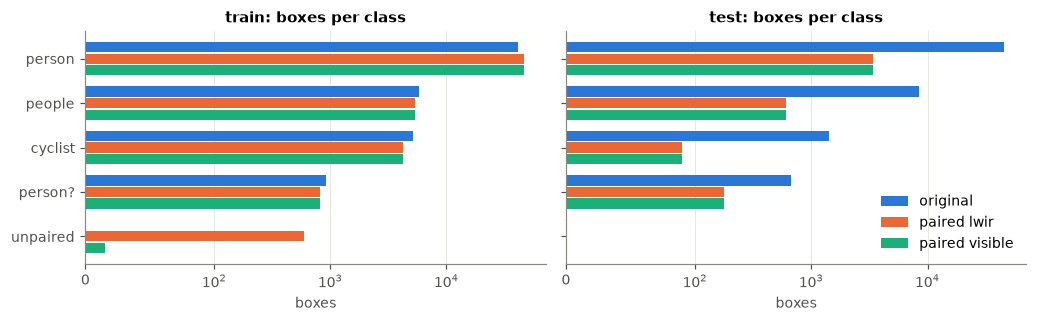

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.0), sharey=True)
y = np.arange(len(CLASSES))
h = 0.26
for ax, split in zip(axes, ["train", "test"]):
    o, p = CC[split]
    for k, (lab, cnt, col) in enumerate([("original", o, C_ORIG), ("paired lwir", p["lwir"], C_LWIR),
                                         ("paired visible", p["visible"], C_VIS)]):
        ax.barh(y + (k - 1) * h, [cnt[c] for c in CLASSES], height=h - 0.03, color=col, label=lab)
    ax.set_title(f"{split}: boxes per class")
    ax.set_xlabel("boxes")
    ax.set_xscale("symlog", linthresh=100)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, CLASSES)
axes[0].invert_yaxis()
axes[1].legend(loc="lower right")
fig.tight_layout()
plt.show()

### Per video

Boxes per class in each video. `orig` = original, `L` = paired lwir, `V` = paired visible. Test videos have far fewer
paired boxes only because paired annotates 1 frame in 20 there.

In [24]:
rows = []
for sv in VIDEOS:
    o = sum(ORIG[sv].values(), Counter())
    p = {m: sum(PAIRED[sv][m].values(), Counter()) for m in MODS}
    row = [vid(sv), SPLIT[sv], TOD[sv], len(IMG[sv]["lwir"])]
    for k in CLASSES[:4]:
        row.append(f"{o[k]:,} / {p['lwir'][k]:,} / {p['visible'][k]:,}")
    row.append(f"{p['lwir']['unpaired']:,} / {p['visible']['unpaired']:,}")
    row.append(f"{sum(o.values()):,} / {sum(p['lwir'].values()):,} / {sum(p['visible'].values()):,}")
    rows.append(row)
md_table(["video", "split", "time", "frames"] + [f"{k} (orig / L / V)" for k in CLASSES[:4]]
         + ["unpaired (L / V)", "all (orig / L / V)"], rows)

| video | split | time | frames | person (orig / L / V) | people (orig / L / V) | cyclist (orig / L / V) | person? (orig / L / V) | unpaired (L / V) | all (orig / L / V) |
|---|---|---|---|---|---|---|---|---|---|
| set00/V000 | train | day | 2,245 | 772 / 780 / 780 | 0 / 0 / 0 | 284 / 284 / 284 | 0 / 0 / 0 | 4 / 0 | 1,056 / 1,068 / 1,064 |
| set00/V001 | train | day | 2,799 | 875 / 890 / 890 | 206 / 202 / 202 | 22 / 22 / 22 | 36 / 21 / 21 | 3 / 0 | 1,139 / 1,138 / 1,135 |
| set00/V002 | train | day | 2,510 | 483 / 484 / 484 | 0 / 0 / 0 | 0 / 0 / 0 | 0 / 0 / 0 | 1 / 3 | 483 / 485 / 487 |
| set00/V003 | train | day | 1,634 | 1,296 / 1,382 / 1,382 | 710 / 599 / 599 | 225 / 223 / 223 | 42 / 47 / 47 | 6 / 0 | 2,273 / 2,257 / 2,251 |
| set00/V004 | train | day | 2,080 | 1,078 / 1,089 / 1,089 | 78 / 78 / 78 | 69 / 68 / 68 | 9 / 8 / 8 | 6 / 0 | 1,234 / 1,249 / 1,243 |
| set00/V005 | train | day | 1,534 | 119 / 119 / 119 | 7 / 7 / 7 | 343 / 343 / 343 | 0 / 0 / 0 | 0 / 0 | 469 / 469 / 469 |
| set00/V006 | train | day | 1,097 | 533 / 520 / 520 | 0 / 0 / 0 | 190 / 190 / 190 | 0 / 0 / 0 | 4 / 0 | 723 / 714 / 710 |
| set00/V007 | train | day | 1,599 | 1,101 / 1,144 / 1,144 | 0 / 0 / 0 | 84 / 71 / 71 | 58 / 58 / 58 | 11 / 0 | 1,243 / 1,284 / 1,273 |
| set00/V008 | train | day | 2,000 | 2,047 / 2,263 / 2,263 | 16 / 0 / 0 | 333 / 255 / 255 | 0 / 0 / 0 | 9 / 0 | 2,396 / 2,527 / 2,518 |
| set01/V000 | train | day | 2,254 | 1,661 / 1,743 / 1,743 | 903 / 749 / 749 | 0 / 281 / 281 | 0 / 0 / 0 | 24 / 0 | 2,564 / 2,797 / 2,773 |
| set01/V001 | train | day | 1,159 | 2,756 / 2,786 / 2,786 | 393 / 423 / 423 | 144 / 117 / 117 | 0 / 17 / 17 | 26 / 0 | 3,293 / 3,369 / 3,343 |
| set01/V002 | train | day | 1,405 | 242 / 173 / 173 | 49 / 28 / 28 | 107 / 107 / 107 | 13 / 14 / 14 | 0 / 0 | 411 / 322 / 322 |
| set01/V003 | train | day | 1,265 | 1,248 / 1,321 / 1,321 | 55 / 60 / 60 | 283 / 118 / 118 | 0 / 18 / 18 | 42 / 0 | 1,586 / 1,559 / 1,517 |
| set01/V004 | train | day | 1,651 | 380 / 393 / 393 | 0 / 0 / 0 | 126 / 46 / 46 | 0 / 0 / 0 | 3 / 6 | 506 / 442 / 445 |
| set01/V005 | train | day | 301 | 156 / 113 / 113 | 0 / 0 / 0 | 34 / 34 / 34 | 0 / 0 / 0 | 0 / 0 | 190 / 147 / 147 |
| set02/V000 | train | day | 1,902 | 1,492 / 1,694 / 1,694 | 385 / 295 / 295 | 0 / 0 / 0 | 0 / 0 / 0 | 30 / 2 | 1,877 / 2,019 / 1,991 |
| set02/V001 | train | day | 1,861 | 3,251 / 3,443 / 3,443 | 0 / 109 / 109 | 319 / 162 / 162 | 109 / 71 / 71 | 52 / 1 | 3,679 / 3,837 / 3,786 |
| set02/V002 | train | day | 1,400 | 2,437 / 2,639 / 2,639 | 61 / 111 / 111 | 146 / 141 / 141 | 0 / 0 / 0 | 52 / 0 | 2,644 / 2,943 / 2,891 |
| set02/V003 | train | day | 1,000 | 1,561 / 1,592 / 1,592 | 219 / 212 / 212 | 4 / 4 / 4 | 48 / 50 / 50 | 44 / 0 | 1,832 / 1,902 / 1,858 |
| set02/V004 | train | day | 1,703 | 1,197 / 1,347 / 1,347 | 86 / 274 / 274 | 139 / 140 / 140 | 39 / 98 / 98 | 92 / 0 | 1,461 / 1,951 / 1,859 |
| set03/V000 | train | night | 4,400 | 2,568 / 2,632 / 2,632 | 31 / 89 / 89 | 577 / 571 / 571 | 1 / 17 / 17 | 21 / 0 | 3,177 / 3,330 / 3,309 |
| set03/V001 | train | night | 2,268 | 3,713 / 3,991 / 3,991 | 377 / 47 / 47 | 151 / 107 / 107 | 0 / 7 / 7 | 65 / 0 | 4,241 / 4,217 / 4,152 |
| set04/V000 | train | night | 3,997 | 2,757 / 4,458 / 4,458 | 1,941 / 1,731 / 1,731 | 161 / 156 / 156 | 136 / 45 / 45 | 25 / 0 | 4,995 / 6,415 / 6,390 |
| set04/V001 | train | night | 3,200 | 3,679 / 4,379 / 4,379 | 189 / 157 / 157 | 1,287 / 695 / 695 | 11 / 38 / 38 | 20 / 0 | 5,166 / 5,289 / 5,269 |
| set05/V000 | train | night | 2,920 | 4,070 / 5,030 / 5,030 | 72 / 138 / 138 | 96 / 124 / 124 | 417 / 299 / 299 | 48 / 3 | 4,655 / 5,639 / 5,594 |
| set06/V000 | test | day | 1,523 | 1,277 / 99 / 99 | 94 / 3 / 3 | 0 / 0 / 0 | 2 / 2 / 2 | 0 / 0 | 1,373 / 104 / 104 |
| set06/V001 | test | day | 2,691 | 2,394 / 140 / 140 | 96 / 8 / 8 | 0 / 0 / 0 | 8 / 8 / 8 | 0 / 0 | 2,498 / 156 / 156 |
| set06/V002 | test | day | 1,688 | 985 / 57 / 57 | 57 / 2 / 2 | 86 / 5 / 5 | 1 / 1 / 1 | 0 / 0 | 1,129 / 65 / 65 |
| set06/V003 | test | day | 4,285 | 4,321 / 316 / 316 | 542 / 25 / 25 | 325 / 17 / 17 | 201 / 17 / 17 | 0 / 0 | 5,389 / 375 / 375 |
| set06/V004 | test | day | 2,800 | 1,349 / 85 / 85 | 331 / 21 / 21 | 19 / 1 / 1 | 230 / 34 / 34 | 0 / 0 | 1,929 / 141 / 141 |
| set07/V000 | test | day | 2,544 | 1,162 / 88 / 88 | 33 / 10 / 10 | 71 / 4 / 4 | 6 / 3 / 3 | 0 / 0 | 1,272 / 105 / 105 |
| set07/V001 | test | day | 4,000 | 797 / 78 / 78 | 580 / 26 / 26 | 35 / 4 / 4 | 6 / 6 / 6 | 0 / 0 | 1,418 / 114 / 114 |
| set07/V002 | test | day | 1,597 | 1,570 / 109 / 109 | 39 / 13 / 13 | 49 / 3 / 3 | 9 / 9 / 9 | 0 / 0 | 1,667 / 134 / 134 |
| set08/V000 | test | day | 2,578 | 5,998 / 353 / 353 | 670 / 41 / 41 | 133 / 5 / 5 | 37 / 16 / 16 | 0 / 0 | 6,838 / 415 / 415 |
| set08/V001 | test | day | 2,972 | 6,342 / 702 / 702 | 1,942 / 133 / 133 | 85 / 22 / 22 | 47 / 11 / 11 | 0 / 0 | 8,416 / 868 / 868 |
| set08/V002 | test | day | 2,500 | 7,685 / 353 / 353 | 812 / 61 / 61 | 35 / 2 / 2 | 65 / 16 / 16 | 0 / 0 | 8,597 / 432 / 432 |
| set09/V000 | test | night | 3,500 | 2,539 / 191 / 191 | 891 / 55 / 55 | 227 / 12 / 12 | 21 / 21 / 21 | 0 / 0 | 3,678 / 279 / 279 |
| set10/V000 | test | night | 4,708 | 1,566 / 194 / 194 | 1,010 / 67 / 67 | 0 / 0 / 0 | 19 / 19 / 19 | 0 / 0 | 2,595 / 280 / 280 |
| set10/V001 | test | night | 4,194 | 1,878 / 117 / 117 | 392 / 26 / 26 | 315 / 13 / 13 | 6 / 6 / 6 | 0 / 0 | 2,591 / 162 / 162 |
| set11/V000 | test | night | 2,020 | 4,806 / 408 / 408 | 526 / 81 / 81 | 34 / 2 / 2 | 4 / 4 / 4 | 0 / 0 | 5,370 / 495 / 495 |
| set11/V001 | test | night | 1,540 | 1,156 / 94 / 94 | 416 / 31 / 31 | 0 / 0 / 0 | 4 / 4 / 4 | 0 / 0 | 1,576 / 129 / 129 |

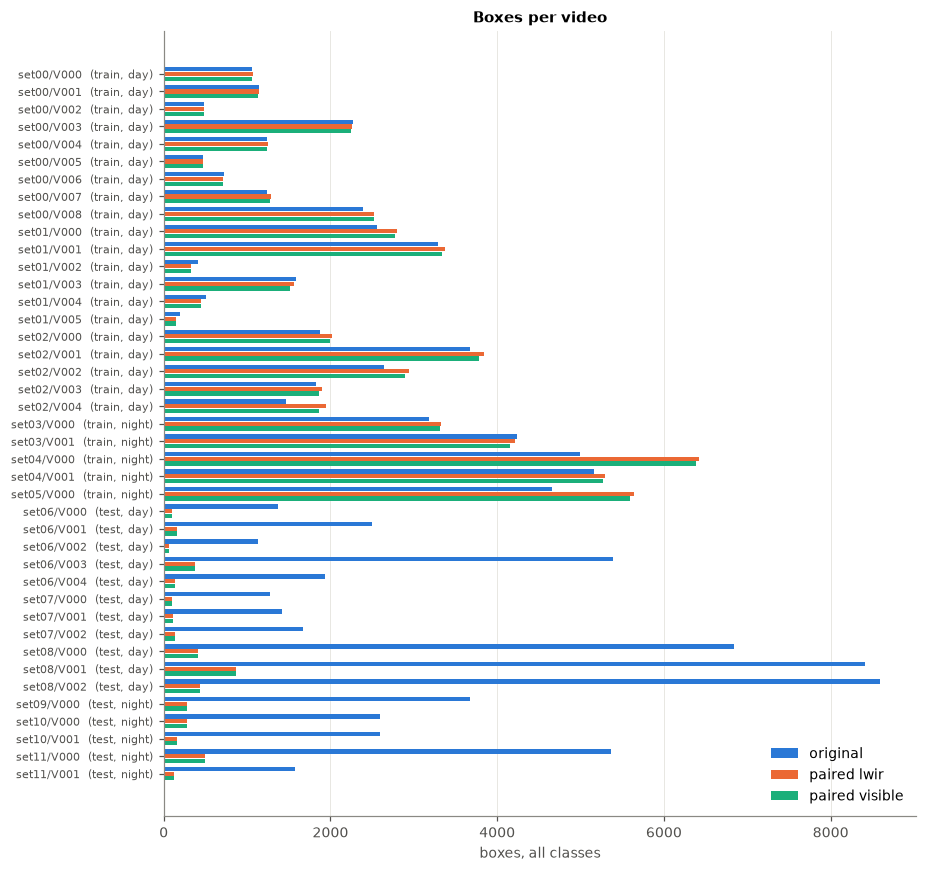

In [25]:
fig, ax = plt.subplots(figsize=(8.5, 8.0))
y = np.arange(len(VIDEOS))
h = 0.27
for k, (lab, get, col) in enumerate([
        ("original", lambda sv: sum(map(n_boxes, ORIG[sv].values())), C_ORIG),
        ("paired lwir", lambda sv: sum(map(n_boxes, PAIRED[sv]["lwir"].values())), C_LWIR),
        ("paired visible", lambda sv: sum(map(n_boxes, PAIRED[sv]["visible"].values())), C_VIS)]):
    ax.barh(y + (k - 1) * h, [get(sv) for sv in VIDEOS], height=h - 0.03, color=col, label=lab)
ax.set_yticks(y, [f"{vid(sv)}  ({SPLIT[sv]}, {TOD[sv]})" for sv in VIDEOS], fontsize=7.5)
ax.invert_yaxis()
ax.set_xlabel("boxes, all classes")
ax.set_title("Boxes per video")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## 4. Clips of 5 frames at ≈ 6 Hz or 5 Hz

A clip is 5 frames, one every `stride` frames of the 20 Hz video: frames *t, t+s, …, t+4s*. KAIST has no per-frame
timestamps, so time comes from the frame index at a nominal 20 Hz. 6 Hz is not a whole stride of 20 Hz, so the two
candidates are:

| stride | rate | step | clip span (first → last frame) |
|---|---|---|---|
| 3 | 6.67 Hz (closest to 6 Hz) | 0.15 s | 0.60 s (13 frames) |
| 4 | 5 Hz | 0.20 s | 0.80 s (17 frames) |

For reference, DINO-Foresight's step is ≈ 0.176 s (F1 audit), between the two.

### 4a. Sampling rate of the paired test annotations

The frame indices tell us the rate directly: the gap between consecutive annotated frames, in 20 Hz frames.

In [26]:
for split in ["train", "test"]:
    gaps = Counter()
    for sv in VIDEOS:
        if SPLIT[sv] != split:
            continue
        f = np.array(sorted(PAIRED[sv]["lwir"]))
        gaps.update(np.diff(f).tolist())
        if split == "test":
            assert f[0] == 19, (vid(sv), f[0])
    rate = {g: f"{FPS / g:g} Hz" for g in gaps}
    print(f"paired {split}: gap between annotated frames (frames: count) {dict(gaps)}  ->  {rate}")

paired train: gap between annotated frames (frames: count) {1: 50159}  ->  {1: '20 Hz'}
paired test: gap between annotated frames (frames: count) {20: 2236}  ->  {20: '1 Hz'}


### 4b. Maximum number of non-overlapping clips

Clips **must not overlap in time**: each one occupies the frame interval *[t, t+4s]*, and no two intervals may share
a frame. (Two clips at the same stride shifted by 1–3 frames would otherwise be near-duplicates.) Among all start
frames *t* that meet a condition, the largest set of disjoint intervals is found greedily by taking the clip that
ends first, then repeating after its end. This is optimal for intervals.

The conditions ask for different things to be labelled:

| condition | context frames 1–4 | last frame (5th, the one a forecaster is scored on) |
|---|---|---|
| **A** all annotated | annotated | annotated |
| **B** all annotated, target has a box | annotated | ≥ 1 box |
| **C** target annotated | image only | annotated |
| **D** target has a box | image only | ≥ 1 box |

*Annotated* means an annotation file exists (it may be empty, a negative frame). For paired, "annotated" and "box"
must hold in **both cameras**. Images exist for every 20 Hz frame, so a context frame always has an image. For the
original set (and paired train), every frame is annotated, so A = C and B = D. They differ only on the paired test
videos.

In [27]:
STRIDES = {3: "6.67 Hz", 4: "5 Hz"}
CLIP_LEN = 5
CONDS = ["A", "B", "C", "D"]


def frame_sets(sv, which):
    # (annotated frames, frames with >= 1 box); paired: in both cameras
    if which == "original":
        ann = set(ORIG[sv])
        box = {f for f, c in ORIG[sv].items() if n_boxes(c) > 0}
    else:
        ann = set(PAIRED[sv]["lwir"]) & set(PAIRED[sv]["visible"])
        box = {f for f in ann if all(n_boxes(PAIRED[sv][m][f]) > 0 for m in MODS)}
    return ann, box


def valid_starts(n_frames, s, ann, box, cond):
    span = (CLIP_LEN - 1) * s
    out = []
    for t in range(0, n_frames - span):
        frames = range(t, t + span + 1, s)
        last = t + span
        if cond in "AB" and not all(f in ann for f in frames):
            continue
        if cond in "AC" and last not in ann:
            continue
        if cond in "BD" and last not in box:
            continue
        out.append(t)
    return out


def max_disjoint(starts, s):
    # greedy by earliest end; every clip has the same length, so earliest end = earliest start
    span = (CLIP_LEN - 1) * s
    chosen, free_from = [], 0
    for t in starts:  # ascending
        if t >= free_from:
            chosen.append(t)
            free_from = t + span + 1
    return chosen


CLIPS = {}  # (which, stride, cond, sv) -> list of start frames
for which in ["original", "paired"]:
    for sv in VIDEOS:
        n = len(IMG[sv]["lwir"])
        ann, box = frame_sets(sv, which)
        for s in STRIDES:
            for cond in CONDS:
                CLIPS[which, s, cond, sv] = max_disjoint(valid_starts(n, s, ann, box, cond), s)

# self-check: chosen clips are disjoint and satisfy their condition
for (which, s, cond, sv), starts in CLIPS.items():
    span = (CLIP_LEN - 1) * s
    assert all(b > a + span for a, b in zip(starts, starts[1:]))
print("OK: all chosen clips are pairwise disjoint in time")

OK: all chosen clips are pairwise disjoint in time


In [28]:
rows = []
for which in ["original", "paired"]:
    for s, hz in STRIDES.items():
        for split in ["train", "test", "all"]:
            svs = [sv for sv in VIDEOS if split == "all" or SPLIT[sv] == split]
            rows.append([which, f"{s} ({hz})", split] + [sum(len(CLIPS[which, s, c, sv]) for sv in svs) for c in CONDS])
md_table(["annotations", "stride", "split", "A all annotated", "B all annotated + target box", "C target annotated",
          "D target box"], rows)

| annotations | stride | split | A all annotated | B all annotated + target box | C target annotated | D target box |
|---|---|---|---|---|---|---|
| original | 3 (6.67 Hz) | train | 3,852 | 1,772 | 3,852 | 1,772 |
| original | 3 (6.67 Hz) | test | 3,465 | 2,049 | 3,465 | 2,049 |
| original | 3 (6.67 Hz) | all | 7,317 | 3,821 | 7,317 | 3,821 |
| original | 4 (5 Hz) | train | 2,941 | 1,377 | 2,941 | 1,377 |
| original | 4 (5 Hz) | test | 2,646 | 1,612 | 2,646 | 1,612 |
| original | 4 (5 Hz) | all | 5,587 | 2,989 | 5,587 | 2,989 |
| paired | 3 (6.67 Hz) | train | 3,852 | 1,739 | 3,852 | 1,739 |
| paired | 3 (6.67 Hz) | test | 0 | 0 | 2,252 | 1,400 |
| paired | 3 (6.67 Hz) | all | 3,852 | 1,739 | 6,104 | 3,139 |
| paired | 4 (5 Hz) | train | 2,941 | 1,349 | 2,941 | 1,349 |
| paired | 4 (5 Hz) | test | 0 | 0 | 2,252 | 1,400 |
| paired | 4 (5 Hz) | all | 2,941 | 1,349 | 5,193 | 2,749 |

### Clips by split and time of day

Conditions **A** (every frame annotated) and **D** (only the target needs a box).

In [29]:
rows = []
for split in ["train", "test"]:
    for tod in ["day", "night"]:
        svs = [sv for sv in VIDEOS if SPLIT[sv] == split and TOD[sv] == tod]
        row = [split, tod]
        for which in ["original", "paired"]:
            for s in STRIDES:
                row.append(" / ".join(f"{sum(len(CLIPS[which, s, c, sv]) for sv in svs):,}" for c in "AD"))
        rows.append(row)
md_table(["split", "time"] + [f"{w} @ {STRIDES[s]} (A / D)" for w in ["original", "paired"] for s in STRIDES], rows)

| split | time | original @ 6.67 Hz (A / D) | original @ 5 Hz (A / D) | paired @ 6.67 Hz (A / D) | paired @ 5 Hz (A / D) |
|---|---|---|---|---|---|
| train | day | 2,563 / 1,130 | 1,956 / 880 | 2,563 / 1,106 | 1,956 / 860 |
| train | night | 1,289 / 642 | 985 / 497 | 1,289 / 633 | 985 / 489 |
| test | day | 2,239 / 1,354 | 1,711 / 1,058 | 0 / 911 | 0 / 911 |
| test | night | 1,226 / 695 | 935 / 554 | 0 / 489 | 0 / 489 |

### Clips per video

Each cell is `A / B / C / D`.

In [30]:
rows = []
for sv in VIDEOS:
    row = [vid(sv), SPLIT[sv], TOD[sv], len(IMG[sv]["lwir"])]
    for which in ["original", "paired"]:
        for s in STRIDES:
            row.append(" / ".join(f"{len(CLIPS[which, s, c, sv]):,}" for c in CONDS))
    rows.append(row)
md_table(["video", "split", "time", "frames"]
         + [f"{w} @ {STRIDES[s]} (A / B / C / D)" for w in ["original", "paired"] for s in STRIDES], rows)

| video | split | time | frames | original @ 6.67 Hz (A / B / C / D) | original @ 5 Hz (A / B / C / D) | paired @ 6.67 Hz (A / B / C / D) | paired @ 5 Hz (A / B / C / D) |
|---|---|---|---|---|---|---|---|
| set00/V000 | train | day | 2,245 | 172 / 62 / 172 / 62 | 132 / 48 / 132 / 48 | 172 / 62 / 172 / 62 | 132 / 48 / 132 / 48 |
| set00/V001 | train | day | 2,799 | 215 / 65 / 215 / 65 | 164 / 51 / 164 / 51 | 215 / 64 / 215 / 64 | 164 / 51 / 164 / 51 |
| set00/V002 | train | day | 2,510 | 193 / 35 / 193 / 35 | 147 / 28 / 147 / 28 | 193 / 35 / 193 / 35 | 147 / 28 / 147 / 28 |
| set00/V003 | train | day | 1,634 | 125 / 67 / 125 / 67 | 96 / 52 / 96 / 52 | 125 / 67 / 125 / 67 | 96 / 51 / 96 / 51 |
| set00/V004 | train | day | 2,080 | 160 / 63 / 160 / 63 | 122 / 49 / 122 / 49 | 160 / 62 / 160 / 62 | 122 / 48 / 122 / 48 |
| set00/V005 | train | day | 1,534 | 118 / 20 / 118 / 20 | 90 / 16 / 90 / 16 | 118 / 20 / 118 / 20 | 90 / 16 / 90 / 16 |
| set00/V006 | train | day | 1,097 | 84 / 31 / 84 / 31 | 64 / 24 / 64 / 24 | 84 / 31 / 84 / 31 | 64 / 24 / 64 / 24 |
| set00/V007 | train | day | 1,599 | 123 / 46 / 123 / 46 | 94 / 36 / 94 / 36 | 123 / 44 / 123 / 44 | 94 / 34 / 94 / 34 |
| set00/V008 | train | day | 2,000 | 153 / 77 / 153 / 77 | 117 / 60 / 117 / 60 | 153 / 77 / 153 / 77 | 117 / 60 / 117 / 60 |
| set01/V000 | train | day | 2,254 | 173 / 70 / 173 / 70 | 132 / 54 / 132 / 54 | 173 / 70 / 173 / 70 | 132 / 54 / 132 / 54 |
| set01/V001 | train | day | 1,159 | 89 / 79 / 89 / 79 | 68 / 61 / 68 / 61 | 89 / 74 / 89 / 74 | 68 / 58 / 68 / 58 |
| set01/V002 | train | day | 1,405 | 108 / 24 / 108 / 24 | 82 / 19 / 82 / 19 | 108 / 21 / 108 / 21 | 82 / 16 / 82 / 16 |
| set01/V003 | train | day | 1,265 | 97 / 47 / 97 / 47 | 74 / 37 / 74 / 37 | 97 / 44 / 97 / 44 | 74 / 33 / 74 / 33 |
| set01/V004 | train | day | 1,651 | 127 / 17 / 127 / 17 | 97 / 13 / 97 / 13 | 127 / 17 / 127 / 17 | 97 / 13 / 97 / 13 |
| set01/V005 | train | day | 301 | 23 / 10 / 23 / 10 | 17 / 7 / 17 / 7 | 23 / 10 / 23 / 10 | 17 / 7 / 17 / 7 |
| set02/V000 | train | day | 1,902 | 146 / 88 / 146 / 88 | 111 / 68 / 111 / 68 | 146 / 88 / 146 / 88 | 111 / 67 / 111 / 67 |
| set02/V001 | train | day | 1,861 | 143 / 95 / 143 / 95 | 109 / 74 / 109 / 74 | 143 / 95 / 143 / 95 | 109 / 74 / 109 / 74 |
| set02/V002 | train | day | 1,400 | 107 / 94 / 107 / 94 | 82 / 72 / 82 / 72 | 107 / 91 / 107 / 91 | 82 / 72 / 82 / 72 |
| set02/V003 | train | day | 1,000 | 76 / 72 / 76 / 72 | 58 / 55 / 58 / 55 | 76 / 70 / 76 / 70 | 58 / 54 / 58 / 54 |
| set02/V004 | train | day | 1,703 | 131 / 68 / 131 / 68 | 100 / 56 / 100 / 56 | 131 / 64 / 131 / 64 | 100 / 52 / 100 / 52 |
| set03/V000 | train | night | 4,400 | 338 / 126 / 338 / 126 | 258 / 97 / 258 / 97 | 338 / 121 / 338 / 121 | 258 / 92 / 258 / 92 |
| set03/V001 | train | night | 2,268 | 174 / 114 / 174 / 114 | 133 / 87 / 133 / 87 | 174 / 108 / 174 / 108 | 133 / 83 / 133 / 83 |
| set04/V000 | train | night | 3,997 | 307 / 149 / 307 / 149 | 235 / 116 / 235 / 116 | 307 / 150 / 307 / 150 | 235 / 116 / 235 / 116 |
| set04/V001 | train | night | 3,200 | 246 / 117 / 246 / 117 | 188 / 92 / 188 / 92 | 246 / 118 / 246 / 118 | 188 / 93 / 188 / 93 |
| set05/V000 | train | night | 2,920 | 224 / 136 / 224 / 136 | 171 / 105 / 171 / 105 | 224 / 136 / 224 / 136 | 171 / 105 / 171 / 105 |
| set06/V000 | test | day | 1,523 | 117 / 87 / 117 / 87 | 89 / 68 / 89 / 68 | 0 / 0 / 76 / 58 | 0 / 0 / 76 / 58 |
| set06/V001 | test | day | 2,691 | 207 / 59 / 207 / 59 | 158 / 46 / 158 / 46 | 0 / 0 / 134 / 40 | 0 / 0 / 134 / 40 |
| set06/V002 | test | day | 1,688 | 129 / 63 / 129 / 63 | 99 / 49 / 99 / 49 | 0 / 0 / 84 / 40 | 0 / 0 / 84 / 40 |
| set06/V003 | test | day | 4,285 | 329 / 230 / 329 / 230 | 252 / 181 / 252 / 181 | 0 / 0 / 214 / 159 | 0 / 0 / 214 / 159 |
| set06/V004 | test | day | 2,800 | 215 / 123 / 215 / 123 | 164 / 96 / 164 / 96 | 0 / 0 / 140 / 85 | 0 / 0 / 140 / 85 |
| set07/V000 | test | day | 2,544 | 195 / 74 / 195 / 74 | 149 / 61 / 149 / 61 | 0 / 0 / 127 / 52 | 0 / 0 / 127 / 52 |
| set07/V001 | test | day | 4,000 | 307 / 107 / 307 / 107 | 235 / 86 / 235 / 86 | 0 / 0 / 200 / 72 | 0 / 0 / 200 / 72 |
| set07/V002 | test | day | 1,597 | 122 / 76 / 122 / 76 | 93 / 58 / 93 / 58 | 0 / 0 / 79 / 50 | 0 / 0 / 79 / 50 |
| set08/V000 | test | day | 2,578 | 198 / 176 / 198 / 176 | 151 / 134 / 151 / 134 | 0 / 0 / 128 / 113 | 0 / 0 / 128 / 113 |
| set08/V001 | test | day | 2,972 | 228 / 186 / 228 / 186 | 174 / 147 / 174 / 147 | 0 / 0 / 148 / 129 | 0 / 0 / 148 / 129 |
| set08/V002 | test | day | 2,500 | 192 / 173 / 192 / 173 | 147 / 132 / 147 / 132 | 0 / 0 / 125 / 113 | 0 / 0 / 125 / 113 |
| set09/V000 | test | night | 3,500 | 269 / 165 / 269 / 165 | 205 / 128 / 205 / 128 | 0 / 0 / 175 / 114 | 0 / 0 / 175 / 114 |
| set10/V000 | test | night | 4,708 | 362 / 175 / 362 / 175 | 276 / 146 / 276 / 146 | 0 / 0 / 235 / 132 | 0 / 0 / 235 / 132 |
| set10/V001 | test | night | 4,194 | 322 / 125 / 322 / 125 | 246 / 99 / 246 / 99 | 0 / 0 / 209 / 83 | 0 / 0 / 209 / 83 |
| set11/V000 | test | night | 2,020 | 155 / 147 / 155 / 147 | 118 / 114 / 118 / 114 | 0 / 0 / 101 / 101 | 0 / 0 / 101 / 101 |
| set11/V001 | test | night | 1,540 | 118 / 83 / 118 / 83 | 90 / 67 / 90 / 67 | 0 / 0 / 77 / 59 | 0 / 0 / 77 / 59 |

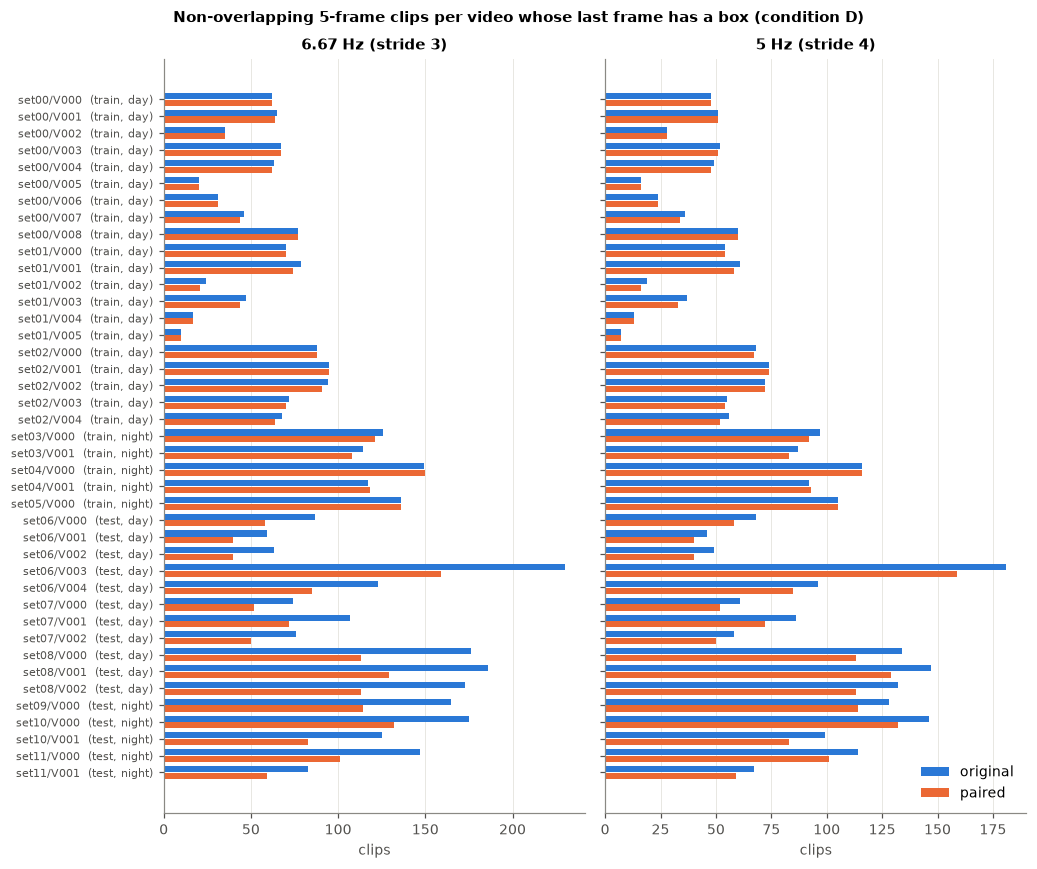

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 8.0), sharey=True)
y = np.arange(len(VIDEOS))
h = 0.4
for ax, (s, hz) in zip(axes, STRIDES.items()):
    for k, (which, col) in enumerate([("original", C_ORIG), ("paired", C_LWIR)]):
        ax.barh(y + (k - 0.5) * h, [len(CLIPS[which, s, "D", sv]) for sv in VIDEOS], height=h - 0.04, color=col,
                label=which)
    ax.set_title(f"{hz} (stride {s})")
    ax.set_xlabel("clips")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, [f"{vid(sv)}  ({SPLIT[sv]}, {TOD[sv]})" for sv in VIDEOS], fontsize=7.5)
axes[0].invert_yaxis()
axes[1].legend(loc="lower right")
fig.suptitle("Non-overlapping 5-frame clips per video whose last frame has a box (condition D)", fontweight="bold",
             fontsize=10)
fig.tight_layout()
plt.show()

## Summary

* **Samples.** Original: **95,324** annotated frames (train 50,184 / test 45,140), every frame of every video;
  45,415 have at least one box. Paired: **52,436** (55 %). That is all 50,184 train frames, but only **2,252 test
  frames (5 %)**, the frames of the standard `test-all-20` list (one in 20, index ≡ 19 mod 20). 23,022 paired frames
  have a box in both cameras.
* **Videos.** **41** in both sets (train 25: 20 day + 5 night; test 16: 11 day + 5 night), 79.4 min at 20 Hz.
* **Objects.** Original 109,629 boxes (person 87,297, people 14,209, cyclist 6,538, person? 1,585). Paired 61,623
  (lwir) / 61,050 (visible), fewer mainly because it covers 5 % of test. On **train**, where both cover the same
  frames, paired has **12 % more `person` boxes** (46,405 vs 41,472) and fewer `people`/`cyclist`. 588 lwir boxes
  and 15 visible boxes are `unpaired`; all other paired boxes have a match in the other camera.
* **Paired test rate.** Consecutive paired test frames are always exactly 20 frames apart (all 2,236 gaps in the 16
  test videos, first frame `I00019`), so at KAIST's 20 Hz they are **1 Hz**. Paired train is 20 Hz (gap 1).
* **Clips (5 frames, never overlapping in time, maximum count).**

  | | 6.67 Hz: A / D | 5 Hz: A / D |
  |---|---|---|
  | original train | 3,852 / 1,772 | 2,941 / 1,377 |
  | original test | 3,465 / 2,049 | 2,646 / 1,612 |
  | paired train | 3,852 / 1,739 | 2,941 / 1,349 |
  | paired test | 0 / 1,400 | 0 / 1,400 |

  A = all 5 frames annotated; D = only the last frame needs a box (context frames need only images).
  * Train counts match between the two sets for A, since paired annotates every train frame. Paired has slightly
    fewer D clips because a box must be present in both cameras.
  * Paired test gives **no** clip with all 5 frames annotated, but each of its 1 Hz frames can end a clip at either
    stride (spans of 13 or 17 frames < 20). That gives 2,252 clips with an annotated target, 1,400 of them with a box.
  * About half the clips' targets have no pedestrian: KAIST is sparse.
* **Implication.** Fully annotated test clips at ≈ 6 Hz can only come from the original annotations. If only the
  scored frame needs labels, paired test gives 1,400 clips whose target has a box, at either rate.